## 0. Chuẩn bị: xuất Excel → CSV

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score, f1_score

SEED = 42
plt.rcParams['figure.dpi'] = 110

# Sheet 'wine.data' chứa dữ liệu; cột đầu là nhãn
XLSX = 'D00_-_wine_data.xlsx'   # đổi đường dẫn nếu cần (Colab: upload file lên)
raw = pd.read_excel(XLSX, sheet_name='wine.data')
raw.columns = [c.strip() for c in raw.columns]      # bỏ khoảng trắng thừa trong tên cột
raw.to_csv('wine_data.csv', index=False)
print('Đã xuất wine_data.csv')

Đã xuất wine_data.csv


## 1. Đọc dữ liệu và khám phá
> Về ghi chú *"loại bỏ cột cuối cùng"* trong file mô tả: sheet dữ liệu có đúng 14 cột = 1 nhãn + 13 thuộc tính nên cột cuối (`13) Proline`) là một thuộc tính thật, **không phải cột thừa** → được giữ lại. Code bên dưới có kiểm tra điều này.

In [2]:
df = pd.read_csv('wine_data.csv')
print('Các cột:', list(df.columns))
print('Số cột thuộc tính =', df.shape[1]-1, '(đúng 13 như mô tả) → không có cột thừa cần bỏ')
df.head()

Các cột: ['Class', '1) Alcohol', '2) Malic acid', '3) Ash', '4) Alcalinity of ash', '5) Magnesium', '6) Total phenols', '7) Flavanoids', '8) Nonflavanoid phenols', '9) Proanthocyanins', '10)Color intensity', '11)Hue', '12)OD280/OD315 of diluted wines', '13)Proline']
Số cột thuộc tính = 13 (đúng 13 như mô tả) → không có cột thừa cần bỏ


,Class,1) Alcohol,2) Malic acid,3) Ash,4) Alcalinity of ash,5) Magnesium,6) Total phenols,7) Flavanoids,8) Nonflavanoid phenols,9) Proanthocyanins,10)Color intensity,11)Hue,12)OD280/OD315 of diluted wines,13)Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


**a) Kích thước và chiều của dữ liệu**

In [3]:
print('Kích thước (n, m) =', df.shape)
print('Số mẫu n =', df.shape[0], '| số cột m =', df.shape[1], '| số chiều dữ liệu (số trục) =', df.ndim)

Kích thước (n, m) = (178, 14)
Số mẫu n = 178 | số cột m = 14 | số chiều dữ liệu (số trục) = 2


**b) Kiểu dữ liệu của các thuộc tính**

In [4]:
print(df.dtypes)
print('\nMissing values:', int(df.isna().sum().sum()))

Class                                int64
1) Alcohol                         float64
2) Malic acid                      float64
3) Ash                             float64
4) Alcalinity of ash               float64
5) Magnesium                         int64
6) Total phenols                   float64
7) Flavanoids                      float64
8) Nonflavanoid phenols            float64
9) Proanthocyanins                 float64
10)Color intensity                 float64
11)Hue                             float64
12)OD280/OD315 of diluted wines    float64
13)Proline                           int64
dtype: object

Missing values: 0


**c) Số lượng thực thể của mỗi giá trị nhãn**

Class
1    59
2    71
3    48
Name: count, dtype: int64


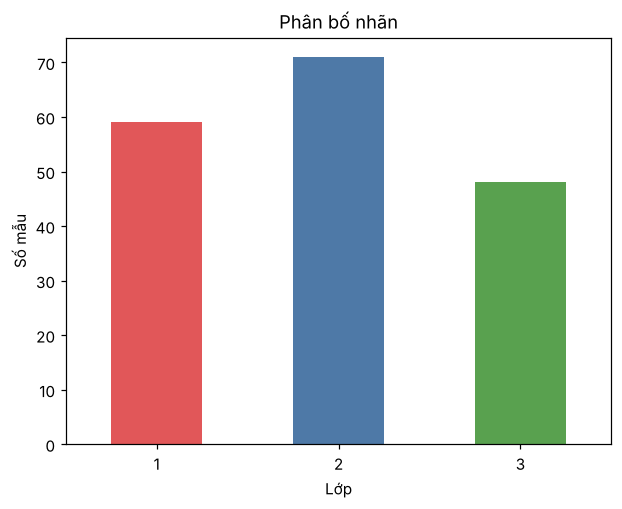

In [5]:
cnt = df['Class'].value_counts().sort_index()
print(cnt)
cnt.plot(kind='bar', color=['#e15759','#4e79a7','#59a14f'], rot=0)
plt.title('Phân bố nhãn'); plt.xlabel('Lớp'); plt.ylabel('Số mẫu'); plt.show()

**d) Giá trị lớn nhất, bé nhất, trung bình của các thuộc tính có giá trị số thực**

In [6]:
feat_cols = [c for c in df.columns if c != 'Class']
float_cols = [c for c in feat_cols if df[c].dtype == 'float64']
print('Các cột kiểu số thực:', len(float_cols), '/', len(feat_cols))
stats = df[feat_cols].agg(['min','max','mean']).T.round(3)
stats.columns = ['Min','Max','Mean']
stats

Các cột kiểu số thực: 11 / 13


,Min,Max,Mean
1) Alcohol,11.03,14.83,13.001
2) Malic acid,0.74,5.80,2.336
3) Ash,1.36,3.23,2.367
4) Alcalinity of ash,10.60,30.00,19.495
5) Magnesium,70.00,162.00,99.742
6) Total phenols,0.98,3.88,2.295
7) Flavanoids,0.34,5.08,2.029
8) Nonflavanoid phenols,0.13,0.66,0.362
9) Proanthocyanins,0.41,3.58,1.591
10)Color intensity,1.28,13.00,5.058


## 2. Tạo data mới và trực quan hóa
- Chỉ lấy các thuộc tính là giá trị liên tục (bỏ cột nhãn).
- Chuẩn hóa → giảm chiều bằng PCA xuống 2D → vẽ, mỗi nhãn một màu.

Phương sai giải thích: [0.362 0.192] → tổng 0.554


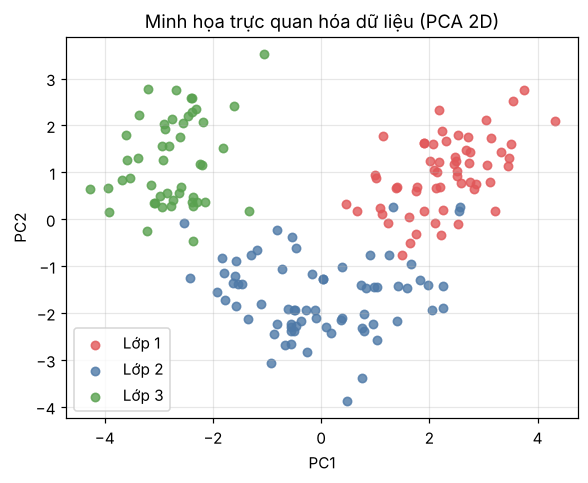

In [7]:
X = df[feat_cols].values
y = df['Class'].values
Xs = StandardScaler().fit_transform(X)

pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(Xs)
print('Phương sai giải thích:', pca.explained_variance_ratio_.round(3), '→ tổng', pca.explained_variance_ratio_.sum().round(3))

colors = {1:'#e15759', 2:'#4e79a7', 3:'#59a14f'}
plt.figure(figsize=(6,4.5))
for k in (1,2,3):
    plt.scatter(Z[y==k,0], Z[y==k,1], c=colors[k], label=f'Lớp {k}', s=30, alpha=.8)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Minh họa trực quan hóa dữ liệu (PCA 2D)')
plt.legend(); plt.grid(alpha=.3); plt.show()

## 3. Huấn luyện mô hình phân lớp
- **k-fold cross validation, k = 10** (StratifiedKFold, xáo trộn, seed cố định).
- 5 mô hình: KNN, **Random Forest**, Naive Bayes, AdaBoost, SVM.
- Tinh chỉnh tham số bằng `GridSearchCV` trên 10 fold với thang đo **F-Score (macro)**.
- Với KNN và SVM (nhạy với thang đo) dùng `Pipeline` có `StandardScaler` để việc chuẩn hóa chỉ học trên tập train của từng fold (tránh rò rỉ dữ liệu).

In [8]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

models = {
 'KNN': (Pipeline([('sc',StandardScaler()),('m',KNeighborsClassifier())]),
         {'m__n_neighbors':[3,5,7,9,11,15], 'm__weights':['uniform','distance'], 'm__p':[1,2]}),
 'Random Forest': (RandomForestClassifier(random_state=SEED),
         {'n_estimators':[50,100,200,300], 'max_depth':[None,3,5,10],
          'min_samples_split':[2,5], 'max_features':['sqrt','log2']}),
 'Naive Bayes': (GaussianNB(), {'var_smoothing':np.logspace(-11,-5,7)}),
 'AdaBoost': (AdaBoostClassifier(random_state=SEED),
         {'n_estimators':[50,100,200], 'learning_rate':[0.01,0.1,0.5,1.0]}),
 'SVM': (Pipeline([('sc',StandardScaler()),('m',SVC())]),
         {'m__C':[0.1,1,10,100], 'm__kernel':['rbf','linear'], 'm__gamma':['scale',0.01,0.1]}),
}

results, best_est = [], {}
for name,(est,grid) in models.items():
    gs = GridSearchCV(est, grid, cv=cv, scoring='f1_macro', n_jobs=-1).fit(X, y)
    best_est[name] = gs.best_estimator_
    bp = {k.replace('m__',''):v for k,v in gs.best_params_.items()}
    results.append({'Mô hình':name, 'Tham số tốt nhất':bp, 'F-Score (k=10)':round(gs.best_score_,4)})
    print(f'{name:14s} F-Score={gs.best_score_:.4f}  params={bp}')

KNN            F-Score=0.9837  params={'n_neighbors': 11, 'p': 1, 'weights': 'uniform'}


Random Forest  F-Score=0.9893  params={'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 50}


Naive Bayes    F-Score=0.9783  params={'var_smoothing': np.float64(1e-11)}


AdaBoost       F-Score=0.9502  params={'learning_rate': 0.5, 'n_estimators': 50}


SVM            F-Score=0.9836  params={'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}


### Bảng so sánh các mô hình (F-Score)

In [9]:
res = pd.DataFrame(results).sort_values('F-Score (k=10)', ascending=False).reset_index(drop=True)
pd.set_option('display.max_colwidth', 100)
res

,Mô hình,Tham số tốt nhất,F-Score (k=10)
0,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 50}",0.9893
1,KNN,"{'n_neighbors': 11, 'p': 1, 'weights': 'uniform'}",0.9837
2,SVM,"{'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}",0.9836
3,Naive Bayes,{'var_smoothing': 1e-11},0.9783
4,AdaBoost,"{'learning_rate': 0.5, 'n_estimators': 50}",0.9502


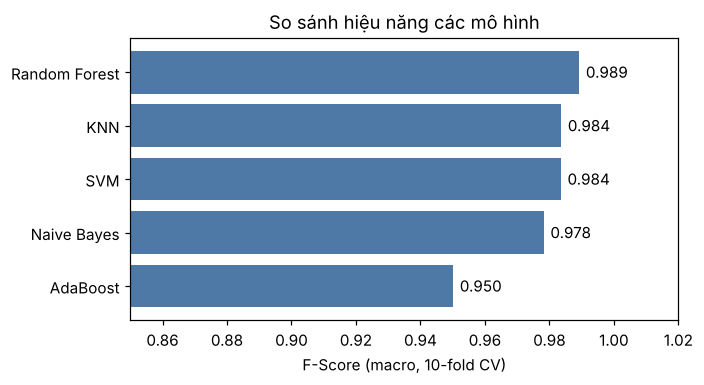

In [10]:
plt.figure(figsize=(6.5,3.6))
bars = plt.barh(res['Mô hình'][::-1], res['F-Score (k=10)'][::-1], color='#4e79a7')
for b in bars: plt.text(b.get_width()+.002, b.get_y()+b.get_height()/2, f'{b.get_width():.3f}', va='center')
plt.xlim(0.85,1.02); plt.xlabel('F-Score (macro, 10-fold CV)'); plt.title('So sánh hiệu năng các mô hình')
plt.tight_layout(); plt.show()

### Phân tích riêng Random Forest
Kiểm tra độ ổn định qua từng fold và tầm quan trọng của các thuộc tính.

F-Score từng fold: [1.    0.944 1.    1.    1.    1.    1.    0.949 1.    1.   ]
Trung bình = 0.9893 ± 0.0215


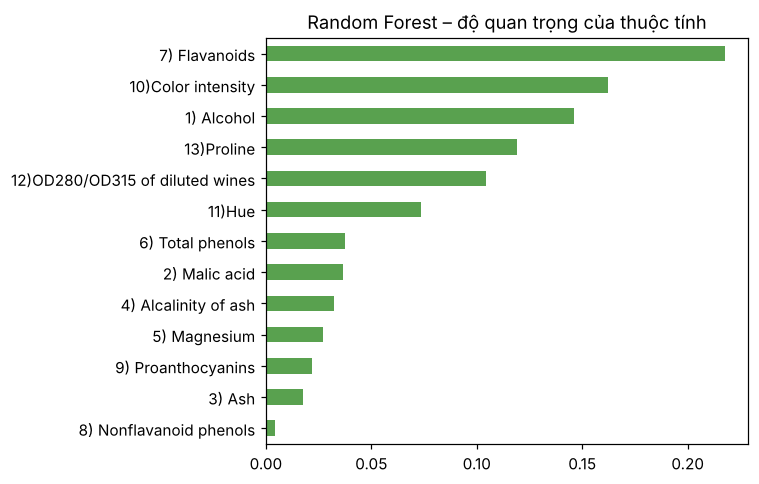

In [11]:
rf = best_est['Random Forest']
fold_f1 = cross_val_score(rf, X, y, cv=cv, scoring='f1_macro')
print('F-Score từng fold:', fold_f1.round(3))
print(f'Trung bình = {fold_f1.mean():.4f} ± {fold_f1.std():.4f}')

rf.fit(X, y)
imp = pd.Series(rf.feature_importances_, index=feat_cols).sort_values()
imp.plot(kind='barh', figsize=(7,4.5), color='#59a14f')
plt.title('Random Forest – độ quan trọng của thuộc tính'); plt.tight_layout(); plt.show()

## 4. Gom cụm
Loại trừ cột nhãn, gom cụm bằng **K-Means** và **DBSCAN** trên dữ liệu đã chuẩn hóa, sau đó dùng nhãn thật để đánh giá bằng **Adjusted Rand Index (ARI)**.

In [12]:
# K-Means (k = 3 vì có 3 giống nho)
km = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(Xs)
ari_km = adjusted_rand_score(y, km.labels_)

# DBSCAN: quét eps / min_samples để chọn cấu hình có ARI cao nhất
best = (-1,None)
rows=[]
for eps in np.arange(1.5, 3.6, 0.1):
    for ms in (3,4,5,6,8,10):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs)
        ncl = len(set(lab))-(1 if -1 in lab else 0)
        if ncl < 2: continue
        a = adjusted_rand_score(y, lab)
        rows.append((round(eps,1), ms, ncl, int((lab==-1).sum()), round(a,4)))
        if a>best[0]: best=(a,(eps,ms))
scan = pd.DataFrame(rows, columns=['eps','min_samples','số cụm','số nhiễu','ARI']).sort_values('ARI',ascending=False)
display(scan.head(5))
eps_b, ms_b = best[1]
db = DBSCAN(eps=eps_b, min_samples=ms_b).fit(Xs)
ari_db = adjusted_rand_score(y, db.labels_)
print(f'DBSCAN chọn eps={eps_b:.1f}, min_samples={ms_b}')

,eps,min_samples,số cụm,số nhiễu,ARI
48,2.5,10,2,32,0.4235
49,2.6,10,2,27,0.4208
43,2.4,5,2,36,0.4205
42,2.4,4,2,33,0.4186
41,2.4,3,2,28,0.4171


DBSCAN chọn eps=2.5, min_samples=10


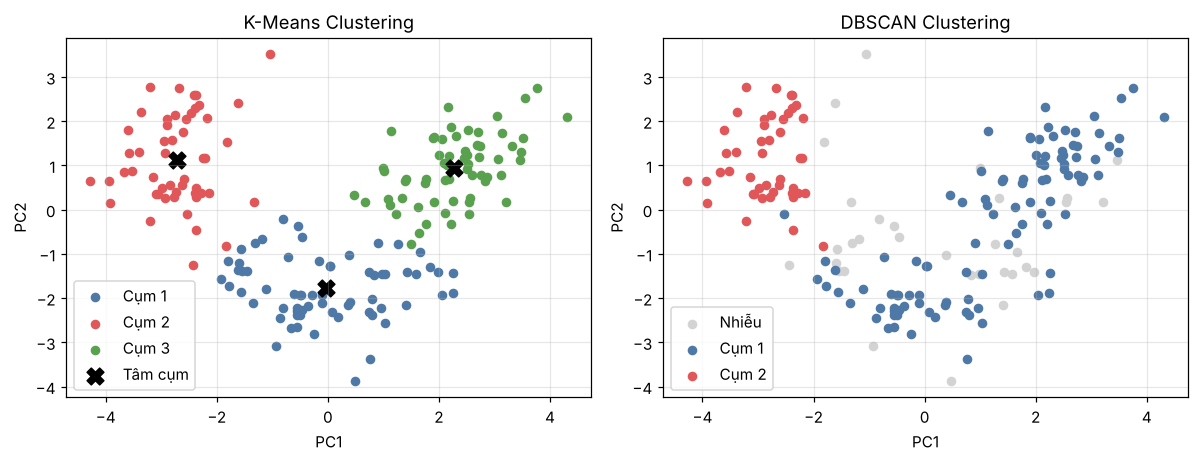

In [13]:
fig, ax = plt.subplots(1,2, figsize=(11,4.3))
pal = ['#4e79a7','#e15759','#59a14f','#f28e2b','#b07aa1']
for k in sorted(set(km.labels_)):
    ax[0].scatter(Z[km.labels_==k,0], Z[km.labels_==k,1], c=pal[k], s=28, label=f'Cụm {k+1}')
c2 = pca.transform(km.cluster_centers_)
ax[0].scatter(c2[:,0], c2[:,1], marker='X', c='k', s=120, label='Tâm cụm')
ax[0].set_title('K-Means Clustering'); ax[0].legend()
for k in sorted(set(db.labels_)):
    m = db.labels_==k
    if k==-1: ax[1].scatter(Z[m,0],Z[m,1],c='lightgray',s=28,label='Nhiễu')
    else: ax[1].scatter(Z[m,0],Z[m,1],c=pal[k%5],s=28,label=f'Cụm {k+1}')
ax[1].set_title('DBSCAN Clustering'); ax[1].legend()
for a in ax: a.set_xlabel('PC1'); a.set_ylabel('PC2'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Bảng đánh giá kết quả gom cụm

In [14]:
pd.DataFrame({'Giải thuật':['K-Means','DBSCAN'],
              'Độ đo':['Adjusted Rand Index']*2,
              'Giá trị':[round(ari_km,4), round(ari_db,4)]})

,Giải thuật,Độ đo,Giá trị
0,K-Means,Adjusted Rand Index,0.8975
1,DBSCAN,Adjusted Rand Index,0.4235


## 5. Kết luận

In [15]:
best_name = res.iloc[0]['Mô hình']
print(f"• Phân lớp: mô hình tốt nhất theo F-Score (10-fold) là {best_name} ({res.iloc[0]['F-Score (k=10)']:.4f}).")
print(f"• Random Forest đạt {res.loc[res['Mô hình']=='Random Forest','F-Score (k=10)'].iloc[0]:.4f}, ổn định giữa các fold (độ lệch chuẩn {fold_f1.std():.3f}).")
print(f"• Gom cụm: K-Means ARI = {ari_km:.3f}; DBSCAN ARI = {ari_db:.3f}.")
print('• Dữ liệu Wine có cấu trúc lớp rõ ràng (3 cụm tách tốt trên PCA) nên K-Means phù hợp hơn DBSCAN khi mật độ giữa các cụm không đồng đều.')

• Phân lớp: mô hình tốt nhất theo F-Score (10-fold) là Random Forest (0.9893).
• Random Forest đạt 0.9893, ổn định giữa các fold (độ lệch chuẩn 0.021).
• Gom cụm: K-Means ARI = 0.897; DBSCAN ARI = 0.424.
• Dữ liệu Wine có cấu trúc lớp rõ ràng (3 cụm tách tốt trên PCA) nên K-Means phù hợp hơn DBSCAN khi mật độ giữa các cụm không đồng đều.
